In [8]:
import numpy as np
import cv2 as cv
from random import randint
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max

In [9]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2


1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

In [10]:
sigma = 30
x = np.arange(0, cols, 1)
y = np.arange(0, rows, 1)
X, Y = np.meshgrid(x, y)
gaussian_mask = np.exp(-((X - ccol)**2 + (Y - crow)**2) / (2 * sigma**2))
high_pass_mask = 1 - gaussian_mask

In [11]:
dft_shift_high_pass = dft_shift * high_pass_mask[:, :, np.newaxis]
f_ishift_high_pass = np.fft.ifftshift(dft_shift_high_pass)
img_back_high_pass = cv.idft(f_ishift_high_pass)
img_back_high_pass = cv.magnitude(img_back_high_pass[:, :, 0], img_back_high_pass[:, :, 1])

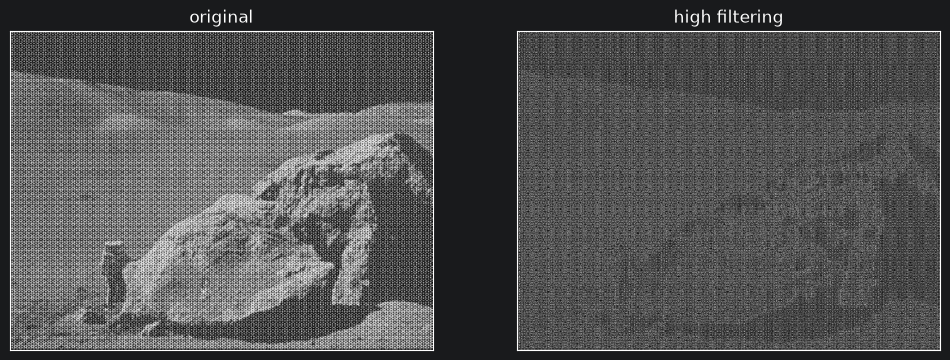

In [12]:
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('original'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_high_pass, cmap='gray')
plt.title('high filtering'), plt.xticks([]), plt.yticks([])
plt.show()

Реализуйте вычисление свертки с помощью преобразования Фурье

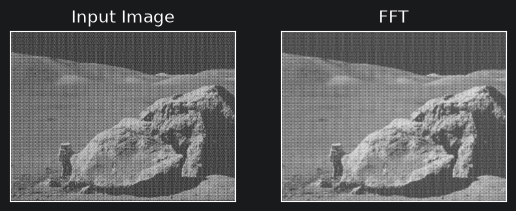

In [13]:
kernel_size = 5
kernel = cv.getGaussianKernel(kernel_size, 0)
kernel = kernel * kernel.T
kernel_rows, kernel_cols = kernel.shape

rows_pad = rows + kernel_rows - 1
cols_pad = cols + kernel_cols - 1

img_padded = np.pad(img, ((0, kernel_rows-1), (0, kernel_cols-1)), mode='constant')

dft_img = cv.dft(np.float32(img_padded), flags=cv.DFT_COMPLEX_OUTPUT)

kernel_padded = np.zeros((rows_pad, cols_pad), dtype=np.float32)
kernel_padded[:kernel_rows, :kernel_cols] = kernel
kernel_f = cv.dft(np.float32(kernel_padded), flags=cv.DFT_COMPLEX_OUTPUT)

conv_f = cv.mulSpectrums(dft_img, kernel_f, 0)
img_conv = cv.idft(conv_f)
img_conv = cv.magnitude(img_conv[:,:,0], img_conv[:,:,1])

img_conv = img_conv[:rows, :cols]
img_conv = cv.normalize(img_conv, None, 0, 255, cv.NORM_MINMAX)

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_conv, cmap = 'gray')
plt.title('FFT'), plt.xticks([]), plt.yticks([])
plt.show()

Реализуйте удаление периодического шума с помощью преобразования Фурье

In [14]:
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))

In [15]:
min_distance = 10
threshold_abs = 270
noise_coords = peak_local_max(magnitude_spectrum, min_distance=min_distance, threshold_abs=threshold_abs)
print(len(noise_coords))

37


In [16]:
radius = 81
mask_noise = np.ones_like(dft_shift)
cv.circle(mask_noise, (ccol, crow), radius + 12, (0, 0), -1)
cv.circle(mask_noise, (ccol, crow), radius - 12, (1, 1), -1);

In [17]:
dft_shift_noise_removed = dft_shift * mask_noise
f_ishift_noise_removed = np.fft.ifftshift(dft_shift_noise_removed)
img_back_noise_removed = cv.idft(f_ishift_noise_removed)
img_back_noise_removed = cv.magnitude(img_back_noise_removed[:, :, 0], img_back_noise_removed[:, :, 1])

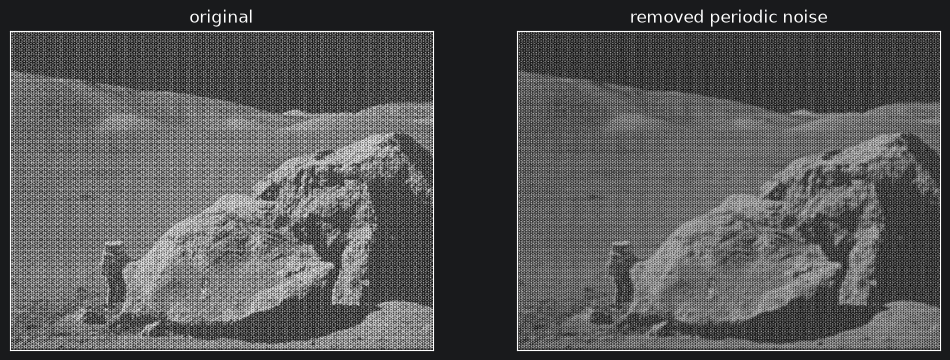

In [18]:
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('original'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_noise_removed, cmap='gray')
plt.title('removed periodic noise'), plt.xticks([]), plt.yticks([])
plt.show()